# 01 · Geo-split Difference-in-Differences + Synthetic Control

**Goal:** recover a *known* incremental lift injected into treated geos, using two independent causal designs.

The synthetic dataset injects a ground-truth lift of **+12%** into treated DMAs during the post/campaign window. A correct estimator should recover it; a naive pre/post comparison should not (it is contaminated by the national market trend).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
os.chdir(os.path.abspath(".."))  # run from repo root so data/ paths resolve
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import generate_data
if not os.path.exists("data/geo_panel.csv"):
    generate_data.main()
df = pd.read_csv("data/geo_panel.csv")
import json
gt = json.load(open("data/ground_truth.json"))
print("Ground-truth injected lift:", f"{gt['true_lift']:+.0%}")
df.head()

Ground-truth injected lift: +12%


,geo,date,day,treated,post,spend,conversions,conversions_counterfactual
0,DMA_00,2025-01-01,0,0,0,0.0,3102.913,3102.913
1,DMA_00,2025-01-02,1,0,0,0.0,3479.592,3479.592
2,DMA_00,2025-01-03,2,0,0,0.0,3530.085,3530.085
3,DMA_00,2025-01-04,3,0,0,0.0,3476.069,3476.069
4,DMA_00,2025-01-05,4,0,0,0.0,3131.462,3131.462


## Difference-in-Differences
We regress `log(conversions)` on a `treated×post` interaction with geo and day fixed effects, clustering standard errors by geo (the unit of randomization). The interaction coefficient, exponentiated, is the % lift.

In [2]:
from src import did
r = did.run_did(df)
naive = did.naive_pre_post(df)
print(f"Naive treated pre/post (BIASED): {naive:+.2%}")
print(f"DiD lift: {r['lift']:+.2%}  95% CI [{r['lift_ci'][0]:+.2%}, {r['lift_ci'][1]:+.2%}]  p={r['pvalue']:.2e}")
print(f"True lift: {gt['true_lift']:+.2%}")

Naive treated pre/post (BIASED): +17.22%
DiD lift: +12.02%  95% CI [+11.34%, +12.70%]  p=1.73e-293
True lift: +12.00%


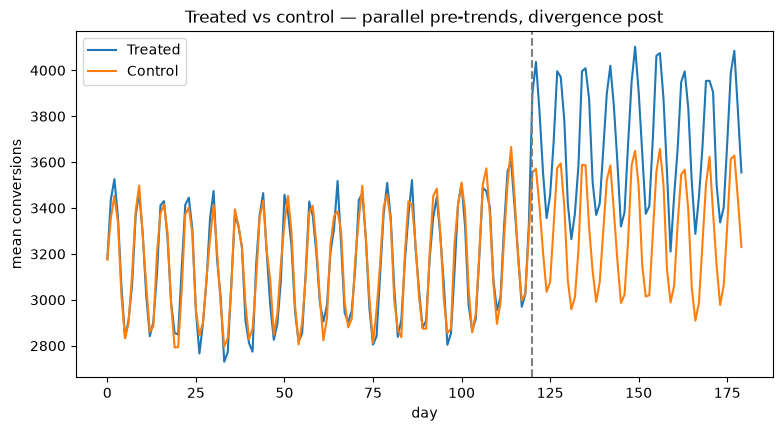

In [3]:
agg = df.groupby(['day','treated'])['conversions'].mean().unstack()
start = df.loc[df['post']==1,'day'].min()
fig, ax = plt.subplots(figsize=(9,4.5))
ax.plot(agg.index, agg[1], label='Treated'); ax.plot(agg.index, agg[0], label='Control')
ax.axvline(start, ls='--', color='grey'); ax.legend(); ax.set_xlabel('day'); ax.set_ylabel('mean conversions')
ax.set_title('Treated vs control — parallel pre-trends, divergence post'); plt.show()

**Read:** treated and control track together pre-campaign (parallel trends assumption holds by construction), then diverge after launch. DiD attributes that gap to media.

## Synthetic Control (validation layer)
Build a virtual control for the pooled treated market as a non-negative, sum-to-one weighted blend of donor (control) geos, fit on the **pre-period only**. The post-period gap is an independent estimate of incremental lift.

In [4]:
from src import synthetic_control as sc
rs = sc.fit_synthetic_control(df)
print(f"Synthetic control lift: {rs['lift']:+.2%}  (pre-fit RMSE={rs['pre_rmse']:.1f})")
top = sorted(rs['weights'].items(), key=lambda kv:-kv[1])[:5]
print('Top donor weights:', top)

Synthetic control lift: +12.32%  (pre-fit RMSE=45.7)
Top donor weights: [('DMA_36', np.float64(0.1267)), ('DMA_16', np.float64(0.0944)), ('DMA_15', np.float64(0.094)), ('DMA_00', np.float64(0.0924)), ('DMA_34', np.float64(0.0902))]


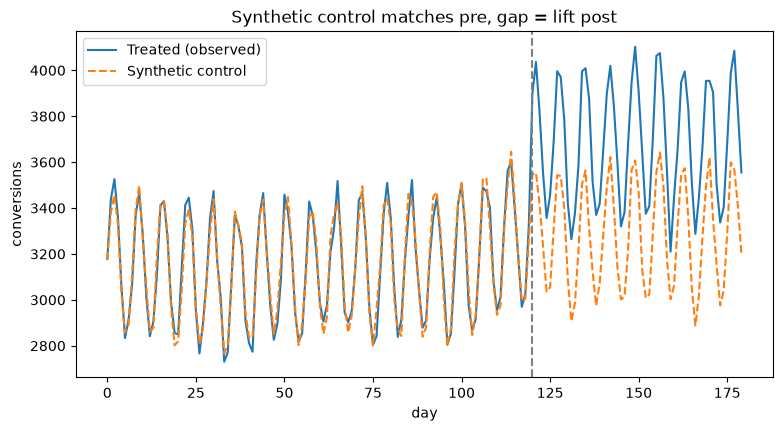

In [5]:
start = rs['campaign_start_day']
fig, ax = plt.subplots(figsize=(9,4.5))
ax.plot(rs['target'].index, rs['target'].values, label='Treated (observed)')
ax.plot(rs['synthetic'].index, rs['synthetic'].values, ls='--', label='Synthetic control')
ax.axvline(start, ls='--', color='grey'); ax.legend(); ax.set_xlabel('day'); ax.set_ylabel('conversions')
ax.set_title('Synthetic control matches pre, gap = lift post'); plt.show()

### Takeaway
Both designs independently recover ~**+12%**, matching the injected ground truth, while the naive pre/post overstates it. This is the core incrementality skill: isolating causal media effect from background trend.